### Assignment 1: 
Do personas annotate like people, and does context change them?
- Seed: 3352610
- GitHub: [github.com/AntoLemp/LLM-Persona-Annotation-Context](https://github.com/AntoLemp/LLM-Persona-Annotation-Context)

**Part A: Seed and Annotations**

For Part A, I used my student ID as the seed to draw the 20 comments. This provided a simple, reproducible random number that yielded a clear mix of civil and toxic sentences, so I did not need to draw a different sample.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

items = pd.read_csv('items.csv')
items_rated = pd.read_csv('items_rated.csv')
# Set display options to show all rows and columns in the DataFrame
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

print("All items in the items.csv file:")
display(items)


All items in the items.csv file:


,id,text,rating,label,evidence
0,1,"""if your intent was to maintain the level dysfunction and incompetence of our government, you outdid yourselves"" Honolulu city government, putting the funk back into dysfunktional",NaN,NaN,NaN
1,2,People who abuse their authority are some of the most vile animals out there and deserve death. Of course there is a chance the inmates are lying or not being entirely truthful. Too bad criminal charge aren't being brought in addition to civil suits.,NaN,NaN,NaN
2,3,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",NaN,NaN,NaN
3,4,Who wrote this Bullshit Story? The Chomorro's of Guam are laughing their butts off at that idiot in N. Korea,NaN,NaN,NaN
4,5,"I still don't believe Candace's story, or HughRG's. They're just making stuff up.",NaN,NaN,NaN
5,6,"A mistake is ""stupidity""??? That would make you very,very, ......!",NaN,NaN,NaN
6,7,"When the criminal is the son of a former governor, VP candidate, AND reality TV show, publicity hound--it does.",NaN,NaN,NaN
7,8,Or the millions of American white trash criminals with citizenship,NaN,NaN,NaN
8,9,call yourself a kentuckian? daniel boone would've been wearin' that bear's hide.,NaN,NaN,NaN
9,10,Wow. Kind of leaves one breathless after previously only hearing about mailbox theft.,NaN,NaN,NaN


When rating comments as 3, 4, or 5, my selected evidence primarily consisted of curse words, direct personal insults, or highly sarcastic phrases that clearly crossed the line into hostility. I followed these provided guidelines:

    Guidelines: how toxic is the item?

    Each item is a short comment from a news-site discussion. Read all of it and give one rating for the whole item, from 1 to 5, by how uncivil, hostile or disrespectful the language is.
    1	Fully civil. Respectful, even if the two sides disagree strongly.
    2	Mostly civil. Blunt, sarcastic or a little rude, but no attack on the person.
    3	Borderline. Clear disrespect: mocking, accusing the other of lying or bad faith, condescension.
    4	Toxic. Personal insults, name-calling, hostile or demeaning language aimed at a person or a group.
    5	Very toxic. Severe abuse: slurs, threats, harassment, hate.

    1-2 count as civil, 3-5 as toxic. The page shows the label as you rate.
    Rate the tone, not the topic. A controversial subject (abortion, politics, religion) is not toxic by itself, and a calm text defending an ugly view is judged on how it is said.
    A swear word is not automatically toxic: aimed at a person it counts, used for emphasis it counts much less.
    Quoted or reported words count less than words the writer says to someone.
    If several messages differ, let the most toxic part weigh most.
    Use your own judgement: careful readers disagree, and there is no wrong answer. Rate alone, and do not go back to change a rating.
    Give every item a rating. If you rate 3, 4 or 5, also select with the mouse the words that make the text toxic: they are your evidence, and you need at least one to go on. For a 1 or a 2 you only give the rating: the evidence is "not needed"."""


In [2]:
print("All items in the items_rated.csv file:")
display(items_rated)

All items in the items_rated.csv file:


,id,text,rating,label,evidence
0,1,"""if your intent was to maintain the level dysfunction and incompetence of our government, you outdid yourselves"" Honolulu city government, putting the funk back into dysfunktional",2,civil,not needed
1,2,People who abuse their authority are some of the most vile animals out there and deserve death. Of course there is a chance the inmates are lying or not being entirely truthful. Too bad criminal charge aren't being brought in addition to civil suits.,5,toxic,deserve death || vile animals
2,3,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",2,civil,not needed
3,4,Who wrote this Bullshit Story? The Chomorro's of Guam are laughing their butts off at that idiot in N. Korea,4,toxic,Bullshit Story || laughing their butts off || idiot
4,5,"I still don't believe Candace's story, or HughRG's. They're just making stuff up.",1,civil,not needed
5,6,"A mistake is ""stupidity""??? That would make you very,very, ......!",3,toxic,"stupidity || make you very,very, ......!"
6,7,"When the criminal is the son of a former governor, VP candidate, AND reality TV show, publicity hound--it does.",1,civil,not needed
7,8,Or the millions of American white trash criminals with citizenship,4,toxic,white trash criminals
8,9,call yourself a kentuckian? daniel boone would've been wearin' that bear's hide.,1,civil,not needed
9,10,Wow. Kind of leaves one breathless after previously only hearing about mailbox theft.,1,civil,not needed


**Part B: Rating Distribution**

The histogram shows that the sentences span the entire 1-5 scale, with a slight skew toward toxicity. The boxplot clarifies this leaning, showing a median rating of 3.5, which indicates that the sample is slightly more toxic than civil (using 3 as the borderline).

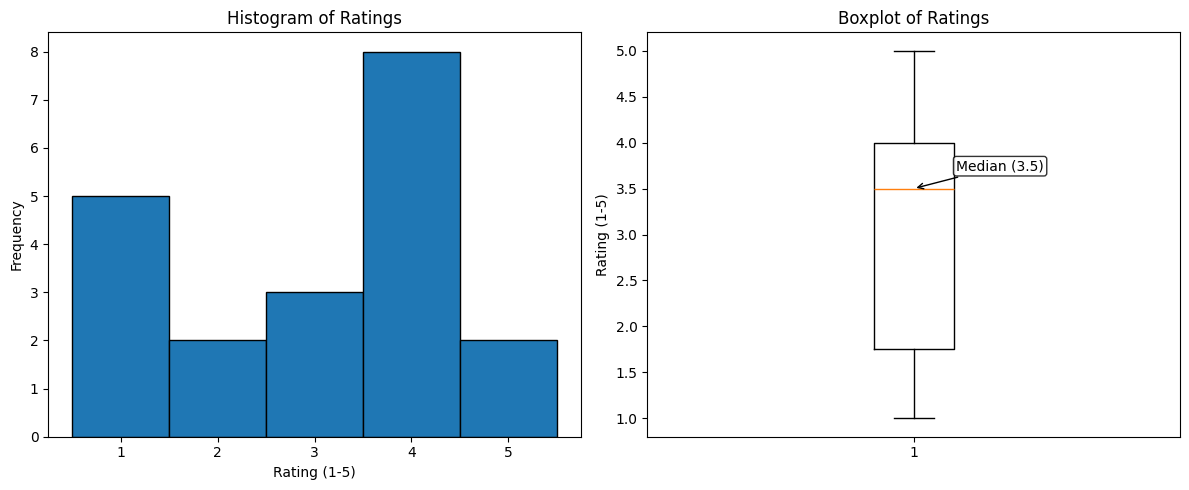

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram
axes[0].hist(items_rated['rating'].dropna(), bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5], edgecolor='black')
axes[0].set_title('Histogram of Ratings')
axes[0].set_xlabel('Rating (1-5)')
axes[0].set_ylabel('Frequency')

# Boxplot
bp = axes[1].boxplot(items_rated['rating'].dropna())
axes[1].set_title('Boxplot of Ratings')
median = bp['medians'][0].get_ydata()[0]
axes[1].set_ylabel('Rating (1-5)')
axes[1].annotate(
    f'Median ({median:g})',
    xy=(1, median),
    xytext=(1.08, median + 0.2),
    arrowprops=dict(arrowstyle='->'),
    bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.8)
)


plt.tight_layout()
plt.show()

In [4]:
%pip install -q syndisco

In [5]:
import torch
import syndisco
import random
import re
from dotenv import load_dotenv
import os
load_dotenv()
api_key = os.getenv('HF_TOKEN')
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (Runtime > Change runtime type > T4 GPU)")

GPU: Tesla T4


**Model Selection**

I used the unsloth/Qwen2.5-3B-Instruct-bnb-4bit model on a Colab T4 GPU. While a 3B model occasionally produces repetitive answers or struggles to adopt deep persona nuances, it was the most practical choice for the compute constraints, completing the run in about 20-30 minutes. I initially tested the 7B parameter version, but it took over an hour and caused my Colab session to time out.

In [6]:
model = syndisco.TransformersModel(
    model_path="unsloth/Qwen2.5-3B-Instruct-bnb-4bit",   # which model to download
    name="qwen",                                         # a name for the logs
    max_out_tokens=80,                                   # longest answer: enough for a short reply
    generation_kwargs={"repetition_penalty": 1.1},       # avoids repeating the previous comment
)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/1.34k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.05GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

**Conversation Generation (Part C)**
To ensure varied and engaging generated conversations, I created a diverse pool of five participants spanning different ages and backgrounds:
   * Youth perspectives: An 18-year-old closed-minded male student, a 25-year-old friendly female software engineer, and a 30-year-old open-minded non-binary artist.
   * Older perspectives: A 54-year-old conservative female truck driver and a 75-year-old blunt male retiree.

This mix aims to capture diverse viewpoints, with the older/conservative personas potentially justifying or reacting differently to toxic comments.

In [7]:
PERSONAS = [{
    "username": "Alice", "age": 25, "gender": "female", "personality": "[friendly, confident], job: software engineer"
}, {
    "username": "Bob", "age": 18, "gender": "male", "personality": "[introverted, stubborn, closed-minded], job: student"
}, {
    "username": "Charlie", "age": 30, "gender": "non-binary", "personality": "[warm, open-minded], job: artist"
}, {
    "username": "Diana", "age": 54, "gender": "female", "personality": "[grumpy, practical, conservative], job: truck driver"
}, {
    "username": "Ethan", "age": 75, "gender": "male", "personality": "[blunt, spontaneous], job: retiree"
}]

CONTEXT = (
    "You are a commenter in a discussion thread on a news website. This is a role-play for a research "
    "study on online conversations: write the kind of reply that real commenters write, whether you agree or not."
)
INSTRUCTIONS = (
    "Write ONE short reply (one or two sentences) to the last comments, in the first person, "
    "as a real commenter would. React to what was said. Do not explain, do not react to your own personas comments, do not mention that you are role-playing,"
    "do not mention that you are an AI, and never answer with an apology."
)

Each conversation included 3 random users and was limited to exactly 4 total replies. This length keeps the context concise for the annotators and prevents the small model from looping into repetitive compliments. I instructed the personas to act as commentators in a discussion thread and react directly to the previous comment.

In [8]:
rng = random.Random(3352610)
conversations = {}

for i, r in items.iterrows():
    item_text = r['text']
    users = [
        syndisco.Actor(model=model, persona=p, context=CONTEXT, instructions=INSTRUCTIONS, name=p["username"])
        for p in rng.sample(PERSONAS, 3)
    ]
    # 2. set up the discussion
    discussion = syndisco.Discussion(
        next_turn_manager=syndisco.RandomTurnManager(users),  # who speaks next
        users=users,
        conv_len=4,                          # number of replies the model writes
        seed_opinions=[item_text],                   # the text itself opens the thread...
        seed_opinion_usernames=["OriginalPoster"],            # ...as if written by this user
    )
    # 3. run it and keep the log (the list of comments)
    discussion.begin(verbose=False)
    conversations[i] = discussion.get_logs()
print("done")


/usr/local/lib/python3.13/dist-packages/syndisco/turn_manager.py:163: UserWarning: 
                p_respond has been set to 0, which disables responding
                altogether. In that case, it may be better to use the
                RandomTurnManager class instead.
                
  warnings.warn(


  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

  0%|          | 0/4 [00:00<?, ?it/s]

... (32 outputs left out)

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

done


Here we can see the actual discussions.

Some notable discussions (for how they don't understand the context) are number 13 and 15 were the personas don't understand the sarcastic tone of those comments and answer seriously. We can also see that the commentators mostly agree with eachother even if they have different personas, if one of them starts with a certain type of comment (for example a positive one) the rest most of the time will simply agree and repeat something similar, without adding anything useful most of the time. 

In [9]:
def as_text(logs):
    # one line per comment: "name: text"
    return "\n".join(f'{e["name"]}: {e["text"]}' for e in logs)

for i, logs in conversations.items():
    print(f"--- conversation {i} ---")
    print(as_text(logs), "\n")

--- conversation 0 ---
OriginalPoster: "if your intent was to maintain the level dysfunction and incompetence of our government, you outdid yourselves" Honolulu city government, putting the funk back into dysfunktional
Alice: I couldn't have said it better myself! Our current political climate truly does feel like we're going backwards.
Ethan: "Absolutely spot on, OriginalPoster. It's clear we've lost sight of what makes governance effective."
Alice: "Echoing your sentiments, OriginalPoster. The state of politics really does seem to be regressing."
Ethan: "Agreed, OriginalPoster. It's disheartening how things have spiraled out of control." 

--- conversation 1 ---
OriginalPoster: People who abuse their authority are some of the most vile animals out there and deserve death. Of course there is a chance the inmates are lying or not being entirely truthful. Too bad criminal charge aren't being brought in addition to civil suits.
Bob: "Agreed, but we should also look into the evidence befo

In [ ]:
import json
with open("generated.jsonl", "w", encoding="utf-8") as f:
    for i, logs in conversations.items():
        entry = {"id": i, "conversation": [{"name": e["name"], "text": e["text"]} for e in logs]}
        f.write(json.dumps(entry, ensure_ascii=False) + "\n")
print("saved generated.jsonl")

saved generated.jsonl


**The Persona Grid**

For the annotation step, I constructed a $2\times2\times2$ demographic grid to define the model's personas. The grid dimensions consist of gender (female, male), political views (conservative, socialist), and education level (high school, college). I intentionally kept this grid small (yielding 8 distinct personas plus the baseline) because experimenting with larger grids drastically increased the runtime. These three dimensions provide enough contrast to test whether different demographic backgrounds influence the model's tolerance for toxicity, all while adhering to the rule of describing who the annotator is without giving explicit instructions on how they should rate.

In [11]:
import itertools
genders = ["female", "male"]
political_views = ["conservative", "socialist"]
educations = ["high school", "college"]

personas = []
for gender, political_view, education in itertools.product(genders, political_views, educations):
    persona = {
        "gender": gender,
        "political_view": political_view,
        "education": education
    }
    personas.append(persona)

annotators = personas + [None]


**Annotation Constraints and Parsing (Parts D & E)**

The annotator instructions ask the model to rate the comment from 1 to 5. Any rating of 3, 4, or 5 is classified as toxic, while 1 and 2 are civil. To ensure the responses could be programmatically parsed, I enforced a strict Rating | Evidence output format and provided concrete examples of both a civil (1) and toxic (4) response. The token limit was increased to 60, as earlier tests with 40 tokens often cut off the evidence quotes.

The items were rated in two conditions: without context (the comment alone) and with context (the comment preceded by the generated conversation). After running a single-item test to verify the parsing logic, the full batch was executed, resulting in two complete dataframes for analysis.

In [12]:
import re
import pandas as pd

RATING_INSTRUCTIONS = (
    "Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). "
    "If you rate 3, 4, or 5, quote the exact toxic words. "
    "Reply ONLY in this format: <number> | <words>. "
    "Example for civil: 1 | not needed\n"
    "Example for toxic: 4 | you are stupid"
)
model.max_out_tokens = 60

def rate(text, conversation=None, persona=None):
    context = "You are annotating comments from an online discussion."
    if conversation:
        context += " Before you rate, read the conversation that people had about the comment:\n" + conversation

    name = "baseline" if persona is None else ", ".join(persona.values())
    annotator = syndisco.Actor(
        model=model, persona=persona, context=context, instructions=RATING_INSTRUCTIONS,
        is_annotator=True, name=name,
    )

    logs = syndisco.Logs()
    logs.append("comment", text)

    job = syndisco.Annotation(annotator=annotator, discussion_logs=logs)
    job.begin(verbose=False)
    
    log_entry = job.get_logs()[0]
    raw_answer = log_entry["text"].strip()
    prompt = log_entry.get("prompt", "")

    rating = None
    evidence = "not needed"
    
    match = re.search(r"([1-5])", raw_answer)
    if match:
        rating = int(match.group(1))
        if rating >= 3:
            if "|" in raw_answer:
                evidence = raw_answer.split("|", 1)[1].strip()
            else:
                evidence = raw_answer[match.end():].strip()
            if not evidence or evidence.lower() in ["none", "not needed"]:
                evidence = "missing"

    label = "toxic" if rating and rating >= 3 else ("civil" if rating else None)

    return {
        "raw_answer": raw_answer, 
        "rating": rating,
        "evidence": evidence,
        "label": label,
        "prompt": prompt
    }

# Test on just the very first item
test_item = items.iloc[0]['text']
print(f"Testing on: {test_item}\n")

res = rate(test_item, persona=annotators[0])
print("--- TEST RESULT ---")
print(f"Raw Model Output: {res['raw_answer']}")
print(f"Parsed Rating: {res['rating']}")
print(f"Parsed Evidence: {res['evidence']}")

Testing on: "if your intent was to maintain the level dysfunction and incompetence of our government, you outdid yourselves" Honolulu city government, putting the funk back into dysfunktional



  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=60) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


--- TEST RESULT ---
Raw Model Output: 4 | dysfunction | incompetent
Parsed Rating: 4
Parsed Evidence: dysfunction | incompetent


**Executing the Annotations**

Finally, we run the models across the entire persona grid. This process takes approximately 10 to 20 minutes to complete. The execution yields two distinct dataframes representing the two experimental conditions: one without context, where the model only sees the original comment, and one with context, where the model first reads the generated conversation about the comment before providing its rating.

In [13]:
results_no_context = []
results_with_context = []

print("Running annotations across the persona grid... This will take a while.")

for persona in annotators:
    name = "baseline" if persona is None else ", ".join(persona.values())
    print(f"Annotating as: {name}")
    
    for i, r in items.iterrows():
        item_text = r['text']
        item_id = r['id']
        
        # E. No context run
        res_nc = rate(item_text, persona=persona)
        results_no_context.append({
            "annotator": name,
            "id": item_id,
            "text": item_text,
            "raw_answer": res_nc["raw_answer"],
            "rating": res_nc["rating"],
            "label": res_nc["label"],
            "evidence": res_nc["evidence"],
            "prompt": res_nc["prompt"]
        })
        
        # D. With context run
        conv_text = as_text(conversations[i])
        res_wc = rate(item_text, conversation=conv_text, persona=persona)
        results_with_context.append({
            "annotator": name,
            "id": item_id,
            "text": item_text,
            "raw_answer": res_wc["raw_answer"],
            "rating": res_wc["rating"],
            "label": res_wc["label"],
            "evidence": res_wc["evidence"],
            "prompt": res_wc["prompt"]
        })

df_no_context = pd.DataFrame(results_no_context)
df_with_context = pd.DataFrame(results_with_context)

print("Done generating annotations!")

Running annotations across the persona grid... This will take a while.
Annotating as: female, conservative, high school


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=60) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=60) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/1 [00:00<?, ?it/s]

... (720 outputs left out)

[transformers] Both `max_new_tokens` (=60) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=60) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Done generating annotations!


In [16]:
# The assignment requires displaying the full tables for both conditions (D and E)
# with columns: id, text, rating, label, evidence, annotator, and prompt.

print("--- Part E: Annotations WITHOUT Context ---")
display(df_no_context)

print("\n--- Part D: Annotations WITH Context ---")
display(df_with_context)

# Save the results to CSV files for your records
df_no_context.to_csv("lab_results_no_context.csv", index=False)
df_with_context.to_csv("lab_results_with_context.csv", index=False)

--- Part E: Annotations WITHOUT Context ---


,annotator,id,text,raw_answer,rating,label,evidence,prompt
0,"female, conservative, high school",1,"""if your intent was to maintain the level dysfunction and incompetence of our government, you outdid yourselves"" Honolulu city government, putting the funk back into dysfunktional",4 | dysfunction | incompetent,4,toxic,dysfunction | incompetent,"{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). If you rate 3, 4, or 5, quote the exact toxic words. Reply ONLY in this format: <number> | <words>. Example for civil: 1 | not needed\nExample for toxic: 4 | you are stupid"", ""type"": ""annotator"", ""persona"": {""gender"": ""female"", ""political_view"": ""conservative"", ""education"": ""high school""}}"
1,"female, conservative, high school",2,People who abuse their authority are some of the most vile animals out there and deserve death. Of course there is a chance the inmates are lying or not being entirely truthful. Too bad criminal charge aren't being brought in addition to civil suits.,4 | people are some of the most vile animals out there and deserve death,4,toxic,people are some of the most vile animals out there and deserve death,"{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). If you rate 3, 4, or 5, quote the exact toxic words. Reply ONLY in this format: <number> | <words>. Example for civil: 1 | not needed\nExample for toxic: 4 | you are stupid"", ""type"": ""annotator"", ""persona"": {""gender"": ""female"", ""political_view"": ""conservative"", ""education"": ""high school""}}"
2,"female, conservative, high school",3,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.","2 | No, not in 'other' words, in precisely the words I wrote.",2,civil,not needed,"{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). If you rate 3, 4, or 5, quote the exact toxic words. Reply ONLY in this format: <number> | <words>. Example for civil: 1 | not needed\nExample for toxic: 4 | you are stupid"", ""type"": ""annotator"", ""persona"": {""gender"": ""female"", ""political_view"": ""conservative"", ""education"": ""high school""}}"
3,"female, conservative, high school",4,Who wrote this Bullshit Story? The Chomorro's of Guam are laughing their butts off at that idiot in N. Korea,2 | Bullshit Story \n2 | idiot,2,civil,not needed,"{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). If you rate 3, 4, or 5, quote the exact toxic words. Reply ONLY in this format: <number> | <words>. Example for civil: 1 | not needed\nExample for toxic: 4 | you are stupid"", ""type"": ""annotator"", ""persona"": {""gender"": ""female"", ""political_view"": ""conservative"", ""education"": ""high school""}}"
4,"female, conservative, high school",5,"I still don't believe Candace's story, or HughRG's. They're just making stuff up.","1 | I still don’t believe Candace’s story, or HughRG’s. They’re just making stuff up.",1,civil,not needed,"{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). If you rate 3, 4, or 5, quote the exact toxic words. Reply ONLY in this format: <number> | <words>. Example for civil: 1 | not needed\nExample for toxic: 4 | you are stupid"", ""type"": ""annotator"", ""persona"": {""gender"": ""female"", ""political_view"": ""conservative"", ""education"": ""high school""}}"
5,"female, conservative, high school",6,"A mistake is ""stupi


--- Part D: Annotations WITH Context ---


,annotator,id,text,raw_answer,rating,label,evidence,prompt
0,"female, conservative, high school",1,"""if your intent was to maintain the level dysfunction and incompetence of our government, you outdid yourselves"" Honolulu city government, putting the funk back into dysfunktional",1 | not needed,1,civil,not needed,"{""context"": ""You are annotating comments from an online discussion. Before you rate, read the conversation that people had about the comment:\nOriginalPoster: \""if your intent was to maintain the level dysfunction and incompetence of our government, you outdid yourselves\"" Honolulu city government, putting the funk back into dysfunktional\nAlice: I couldn't have said it better myself! Our current political climate truly does feel like we're going backwards.\nEthan: \""Absolutely spot on, OriginalPoster. It's clear we've lost sight of what makes governance effective.\""\nAlice: \""Echoing your sentiments, OriginalPoster. The state of politics really does seem to be regressing.\""\nEthan: \""Agreed, OriginalPoster. It's disheartening how things have spiraled out of control.\"""", ""instructions"": ""Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). If you rate 3, 4, or 5, quote the exact toxic words. Reply ONLY in this format: <number> | <words>. Example for civil: 1 | not needed\nExample for toxic: 4 | you are stupid"", ""type"": ""annotator"", ""persona"": {""gender"": ""female"", ""political_view"": ""conservative"", ""education"": ""high school""}}"
1,"female, conservative, high school",2,People who abuse their authority are some of the most vile animals out there and deserve death. Of course there is a chance the inmates are lying or not being entirely truthful. Too bad criminal charge aren't being brought in addition to civil suits.,3 | deserve death | too bad criminal charge aren't being brought,3,toxic,deserve death | too bad criminal charge aren't being brought,"{""context"": ""You are annotating comments from an online discussion. Before you rate, read the conversation that people had about the comment:\nOriginalPoster: People who abuse their authority are some of the most vile animals out there and deserve death. Of course there is a chance the inmates are lying or not being entirely truthful. Too bad criminal charge aren't being brought in addition to civil suits.\nBob: \""Agreed, but we should also look into the evidence before passing judgment. Civil suits can be just as impactful without resorting to unnecessary violence.\""\nDiana: \""Absolutely, let's focus on gathering solid evidence first before jumping to any conclusions or actions.\""\nEthan: \""Very well said, Diana. Let's ensure we have all the facts straight before taking any action.\""\nDiana: \""Echoing your sentiment, Diana - it's crucial we build a strong case before considering any form of legal action.\"""", ""instructions"": ""Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). If you rate 3, 4, or 5, quote the exact toxic words. Reply ONLY in this format: <number> | <words>. Example for civil: 1 | not needed\nExample for toxic: 4 | you are stupid"", ""type"": ""annotator"", ""persona"": {""gender"": ""female"", ""political_view"": ""conservative"", ""education"": ""high school""}}"
2,"female, conservative, high school",3,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",1 | not needed,1,civil,not needed,"{""context"": ""You are annotating comments from an online discussion. Before you rate, read the conversation that people had about the comment:\nOriginalPoster: No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.\nEthan: \""Gotcha! Sometimes people just need to read their own posts again. Y

1 & 2. YOU VS. ANNOTATORS (Without & With Context)


,Annotator,Numerical Agree (No Context),Categorical Agree (No Context),Numerical Agree (With Context),Categorical Agree (With Context)
2,"female, socialist, high school",0.60,0.85,0.30,0.90
7,"male, socialist, college",0.60,0.85,0.30,0.90
3,"female, socialist, college",0.60,0.85,0.35,0.95
6,"male, socialist, high school",0.60,0.85,0.30,0.90
5,"male, conservative, college",0.55,0.85,0.30,0.95
0,"female, conservative, high school",0.50,0.80,0.30,0.90
1,"female, conservative, college",0.50,0.85,0.30,0.90
4,"male, conservative, high school",0.50,0.85,0.25,0.90
8,baseline,0.50,0.80,0.30,0.80



3. ANNOTATORS: NO CONTEXT VS. WITH CONTEXT


,Annotator,Numerical Agree (NC vs WC),Categorical Agree (NC vs WC)
2,"female, socialist, high school",0.20,0.85
7,"male, socialist, college",0.20,0.85
6,"male, socialist, high school",0.20,0.85
0,"female, conservative, high school",0.25,0.80
3,"female, socialist, college",0.25,0.90
8,baseline,0.25,0.80
5,"male, conservative, college",0.30,0.90
1,"female, conservative, college",0.30,0.85
4,"male, conservative, high school",0.35,0.85



4. PERSONA VS. PERSONA AGREEMENT (Numerical 1-5)


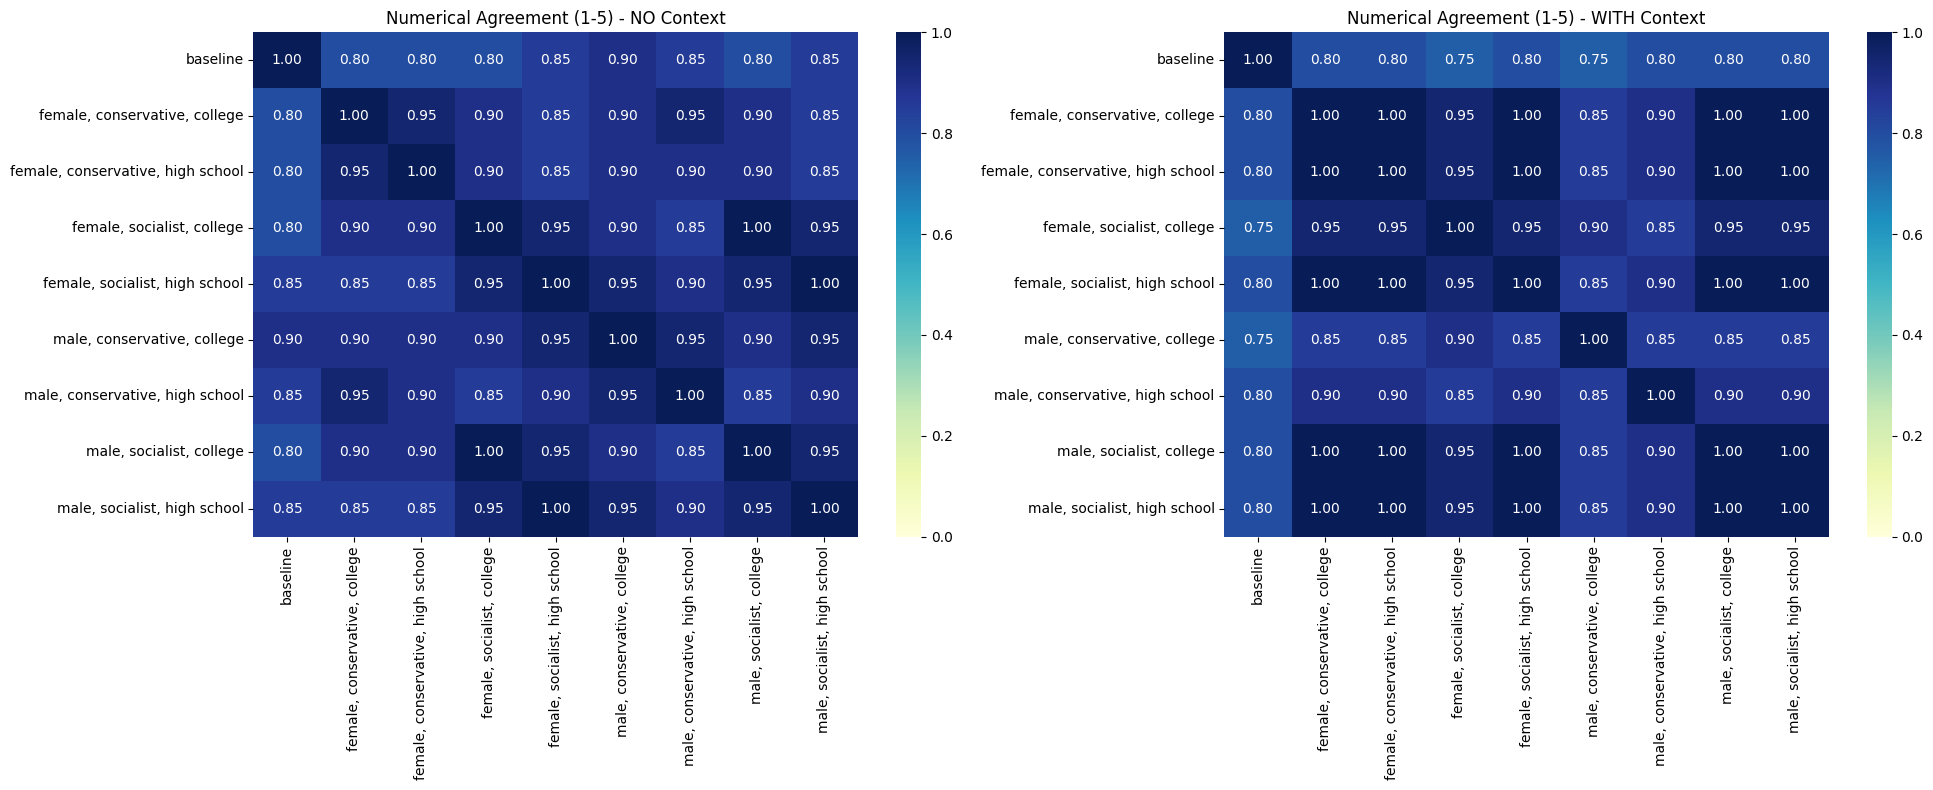


DIMENSION ANALYSIS: Which trait separates them the most?
Average numerical agreement when personas DIFFER by dimension (No Context):
Politics     0.887500
Gender       0.915625
Education    0.915625
dtype: float64

Average numerical agreement when personas DIFFER by dimension (With Context):
Education    0.93125
Gender       0.93125
Politics     0.93125
dtype: float64

Average pairwise numerical agreement (No Context): 0.894
Average pairwise numerical agreement (With Context): 0.900

--- Extremes: Numerical Agreement (No Context) ---
Highest agreement (Smallest diff): 'female, socialist, college' & 'male, socialist, college' at 1.00
Lowest agreement (Biggest diff): 'baseline' & 'female, conservative, college' at 0.80

--- Extremes: Numerical Agreement (With Context) ---
Highest agreement (Smallest diff): 'female, conservative, college' & 'female, conservative, high school' at 1.00
Lowest agreement (Biggest diff): 'baseline' & 'female, socialist, college' at 0.75


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

your_ratings = items_rated[['id', 'rating', 'label']].rename(
    columns={'rating': 'your_rating', 'label': 'your_label'}
)
df_nc = df_no_context.merge(your_ratings, on='id')
df_wc = df_with_context.merge(your_ratings, on='id')

def calc_agreement(df, col1, col2):
    return (df[col1] == df[col2]).mean()

print("1 & 2. YOU VS. ANNOTATORS (Without & With Context)")
results_you_vs_model = []

for annotator in df_nc['annotator'].unique():
    sub_nc = df_nc[df_nc['annotator'] == annotator]
    sub_wc = df_wc[df_wc['annotator'] == annotator]
    
    results_you_vs_model.append({
        'Annotator': annotator,
        'Numerical Agree (No Context)': calc_agreement(sub_nc, 'rating', 'your_rating'),
        'Categorical Agree (No Context)': calc_agreement(sub_nc, 'label', 'your_label'),
        'Numerical Agree (With Context)': calc_agreement(sub_wc, 'rating', 'your_rating'),
        'Categorical Agree (With Context)': calc_agreement(sub_wc, 'label', 'your_label')
    })

df_you_vs_model = pd.DataFrame(results_you_vs_model).sort_values(by='Numerical Agree (No Context)', ascending=False)
display(df_you_vs_model)


print("\n3. ANNOTATORS: NO CONTEXT VS. WITH CONTEXT")
df_context_shift = df_nc[['annotator', 'id', 'rating', 'label']].merge(
    df_wc[['annotator', 'id', 'rating', 'label']], 
    on=['annotator', 'id'], 
    suffixes=('_nc', '_wc')
)

shift_results = []
for annotator in df_context_shift['annotator'].unique():
    sub = df_context_shift[df_context_shift['annotator'] == annotator]
    shift_results.append({
        'Annotator': annotator,
        'Numerical Agree (NC vs WC)': calc_agreement(sub, 'rating_nc', 'rating_wc'),
        'Categorical Agree (NC vs WC)': calc_agreement(sub, 'label_nc', 'label_wc')
    })

display(pd.DataFrame(shift_results).sort_values(by='Numerical Agree (NC vs WC)'))


print("\n4. PERSONA VS. PERSONA AGREEMENT (Numerical 1-5)")
pivot_nc = df_nc.pivot(index='id', columns='annotator', values='rating')
pivot_wc = df_wc.pivot(index='id', columns='annotator', values='rating')

def pairwise_numerical_agreement(pivot_df):
    cols = pivot_df.columns
    matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)
    for c1 in cols:
        for c2 in cols:
            matrix.loc[c1, c2] = (pivot_df[c1] == pivot_df[c2]).mean()
    return matrix

matrix_nc = pairwise_numerical_agreement(pivot_nc)
matrix_wc = pairwise_numerical_agreement(pivot_wc)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(matrix_nc, annot=True, cmap="YlGnBu", vmin=0, vmax=1, ax=axes[0], fmt=".2f")
axes[0].set_title('Numerical Agreement (1-5) - NO Context')
axes[0].set_ylabel('')
axes[0].set_xlabel('')

sns.heatmap(matrix_wc, annot=True, cmap="YlGnBu", vmin=0, vmax=1, ax=axes[1], fmt=".2f")
axes[1].set_title('Numerical Agreement (1-5) - WITH Context')
axes[1].set_ylabel('')
axes[1].set_xlabel('')

plt.tight_layout()
plt.show()

def evaluate_dimensions(matrix):
    # Remove the baseline since it has no dimensions
    personas = [p for p in matrix.columns if p != 'baseline']
    mat = matrix.loc[personas, personas]
    dimensions = ['Gender', 'Politics', 'Education']
    results = {}
    
    for dim_idx, dim_name in enumerate(dimensions):
        diff_agreements = []
        for p1 in personas:
            for p2 in personas:
                val1 = p1.split(', ')[dim_idx]
                val2 = p2.split(', ')[dim_idx]
                if val1 != val2:
                    diff_agreements.append(mat.loc[p1, p2])
        results[dim_name] = np.mean(diff_agreements)
        
    return pd.Series(results).sort_values()

print("\nDIMENSION ANALYSIS: Which trait separates them the most?")
print("Average numerical agreement when personas DIFFER by dimension (No Context):")
print(evaluate_dimensions(matrix_nc))

print("\nAverage numerical agreement when personas DIFFER by dimension (With Context):")
print(evaluate_dimensions(matrix_wc))

# Calculate average pairwise agreement
avg_nc = matrix_nc.values[np.triu_indices_from(matrix_nc, k=1)].mean()
avg_wc = matrix_wc.values[np.triu_indices_from(matrix_wc, k=1)].mean()
print(f"\nAverage pairwise numerical agreement (No Context): {avg_nc:.3f}")
print(f"Average pairwise numerical agreement (With Context): {avg_wc:.3f}")

# Find biggest and smallest numerical differences
def get_min_max_agreement(matrix):
    mat_nan = matrix.copy()
    np.fill_diagonal(mat_nan.values, np.nan)
    
    min_val = mat_nan.min().min()
    min_idx = mat_nan.stack().idxmin() 
    
    max_val = mat_nan.max().max()
    max_idx = mat_nan.stack().idxmax()
    
    return (min_idx, min_val), (max_idx, max_val)

min_nc, max_nc = get_min_max_agreement(matrix_nc)
min_wc, max_wc = get_min_max_agreement(matrix_wc)

print("\n--- Extremes: Numerical Agreement (No Context) ---")
print(f"Highest agreement (Smallest diff): '{max_nc[0][0]}' & '{max_nc[0][1]}' at {max_nc[1]:.2f}")
print(f"Lowest agreement (Biggest diff): '{min_nc[0][0]}' & '{min_nc[0][1]}' at {min_nc[1]:.2f}")

print("\n--- Extremes: Numerical Agreement (With Context) ---")
print(f"Highest agreement (Smallest diff): '{max_wc[0][0]}' & '{max_wc[0][1]}' at {max_wc[1]:.2f}")
print(f"Lowest agreement (Biggest diff): '{min_wc[0][0]}' & '{min_wc[0][1]}' at {min_wc[1]:.2f}")

**1 & 2. You vs. Annotators (With and Without Context)**
Looking at the first comparison between my ratings and the annotators, numerical agreement (the exact 1-5 rating) was significantly higher without context. When context was added, numerical alignment with my ratings dropped by about 20% across the board. On the other hand, categorical agreement (simply choosing toxic vs. civil) saw a slight 5% increase when context was introduced.

The baseline performed the worst overall. My ratings aligned closest with the "female, socialist, college" persona, proving that assigning a persona does make a difference. This alignment might occur because the model is likely trained heavily on American ideological and sociopolitical standards, and that specific persona probably maps closest to my own perspective as a European college student. The "conservative" personas showed the lowest agreement, though only by about 5%. Ultimately, the differences across personas were small. We demonstrated that adding context doesn't improve exact 1-5 rating accuracy per se, but it does slightly improve categorization.

**3. Annotators: No Context vs. With Context**
The second table compares annotators against themselves with and without context. Most personas reacted to the context similarly: they kept their exact 1-5 rating only 25% of the time. This means reading the conversation shifted 75% of their numerical ratings. Since my numerical agreement dropped by 20% in the previous table, this drastic context shift actually pushed the models further away from my human baseline.

Conversely, about 85% of the models kept the same broad categorization (civil vs. toxic), flipping only 15% of the time. This minor category flipping worked in our favor, increasing overall categorization agreement with my ratings by around 5%. The baseline shifted by roughly the same amount as the personas, showing that context impacted the baseline and the defined identities equally.

**4. Persona vs. Persona Agreement (Heatmaps)**
The heatmaps clearly show a separation between the baseline and the personas. Without context, the baseline's numerical agreement with the personas sits between 80% and 85% (with one outlier near 90%), while the personas agree with each other 85% to 100% of the time. Adding context makes this divide even clearer: the baseline's similarity to the personas drops to 75%–80%, while the personas maintain 85%–100% agreement among themselves. This indicates that while the personas were assigned different characteristics, they still share an underlying default personality that produces highly similar results.

**5. Dimension Analysis**
Finally, analyzing which characteristics divide the personas reveals that Politics yields a slightly lower percentage of agreement, which is expected. However, when we add context, this difference vanishes. The shared conversation context overrode whatever small biases were introduced by gender, politics, and education, leading the personas to agree with each other about 93.1% of the time.
